# Tanzania Waterpoint Functionality — Regularized Modeling & Hyperparameter Optimization

This notebook implements an advanced machine learning pipeline to predict waterpoint functionality across Tanzania. To resolve **overfitting** caused by severe class imbalance (functional: 54.3%, non-functional: 38.4%, functional needs repair: 7.3%), this pipeline enforces:
- **Cost-Sensitive Learning & Balanced Class Weighting**: Applied across all models (`class_weight='balanced'`, `auto_class_weights='Balanced'`, and dynamic `compute_sample_weight`).
- **Strict Tree Complexity Regularization**: Shallow tree bounds (`max_depth` <= 6), high leaf sample constraints (`min_child_weight` / `min_child_samples` >= 20-50), and L1/L2 penalties (`reg_alpha`, `reg_lambda`, `l2_leaf_reg`).
- **Comprehensive Multiclass ROC & AUC Evaluation**: One-vs-Rest (OvR) ROC curves for each class, micro/macro averages, and holdout Train vs Test ROC-AUC gap verification.
- **Holdout & Stratified Cross-Validation Diagnostics**: Verifying that the generalization gap between train and test remains minimal (Gap <= 0.035).

## 1. Setup & Environment

### 1.1 Imports & Global Configuration
Configure logging, suppress warnings, set a global random seed (`SEED = 42`), and define search trial budgets for Optuna.


In [1]:
import numpy as np
import pandas as pd
import optuna
import pickle
import warnings
import os
import platform
import sklearn

# Visualization & Plotting
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder, label_binarize
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    fbeta_score, f1_score, recall_score, precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier

from feature_engineer import make_preprocessor, FeatureEngineer, predict_labels, numeric_features, cat_features

# Custom Balanced XGBoost Classifier that automatically applies balanced sample weights in fit()
class BalancedXGBClassifier(xgb.XGBClassifier):
    """XGBClassifier wrapper that automatically computes and applies balanced sample weights in fit()"""
    def fit(self, X, y, sample_weight=None, **fit_params):
        if sample_weight is None:
            sample_weight = compute_sample_weight('balanced', y)
        return super().fit(X, y, sample_weight=sample_weight, **fit_params)

SEED = 42
N_TRIALS = 25 # Number of Optuna tuning trials per model
TEST_SIZE = 0.2
DATA_PATH = r"Dataset\Cleaned\cleaned_data.csv"


c:\Users\Windows 10\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 2. Data Loading & Stratified Partitioning

### 2.1 Ingesting Cleaned Data and Label Encoding
Load `cleaned_data1.csv`, compute the class balance of `status_group`, and apply `LabelEncoder` to transform string target labels into integer indices:
- `0`: `functional` (54.3% majority class)
- `1`: `functional needs repair` (7.3% minority class)
- `2`: `non functional` (38.4%)

Split the dataset into an 80% training set ($N = 47,520$) and a 20% holdout test set ($N = 11,880$) using `stratify=y` to preserve exact class proportions.


In [2]:
df = pd.read_csv(DATA_PATH)
print('Class distribution:'); print(df['status_group'].value_counts(normalize=True).round(3))

X = df.drop('status_group', axis=1)
le = LabelEncoder()
y = le.fit_transform(df['status_group'])
print(dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
print('train:', X_train.shape, '| test:', X_test.shape)


Class distribution:
status_group
functional                 0.543
non functional             0.384
functional needs repair    0.073
Name: proportion, dtype: float64
{'functional': np.int64(0), 'functional needs repair': np.int64(1), 'non functional': np.int64(2)}
train: (47520, 18) | test: (11880, 18)


### 2.2 Inspecting Features
Preview the first 5 records of the feature space.


In [3]:
df.head()


,amount_tsh,funder,gps_height,installer,basin,region,population,public_meeting,scheme_management,permit,extraction_type_class,management_group,payment_type,quality_group,quantity_group,source_class,waterpoint_type_group,status_group,age
0,6000.0,Roman,1390,Roman,Lake Nyasa,Iringa,109,True,VWC,False,gravity,user-group,annually,good,enough,groundwater,communal standpipe,functional,12.0
1,0.0,Grumeti,1399,GRUMETI,Lake Victoria,Mara,280,NaN,Other,True,gravity,user-group,never pay,good,insufficient,surface,communal standpipe,functional,3.0
2,25.0,Lottery Club,686,World vision,Pangani,Manyara,250,True,VWC,True,gravity,user-group,per bucket,good,enough,surface,communal standpipe,functional,4.0
3,0.0,Unicef,263,UNICEF,Ruvuma / Southern Coast,Mtwara,58,True,VWC,True,submersible,user-group,never pay,good,dry,groundwater,communal standpipe,non functional,27.0
4,0.0,Action In A,0,Artisan,Lake Victoria,Kagera,0,True,NaN,True,gravity,other,never pay,good,seasonal,surface,communal standpipe,functional,13.0


## 3. Modular Feature Engineering Pipeline

### 3.1 Writing the Reusable Feature Engineering Module (`feature_engineer.py`)
To ensure high software modularity, reproducibility, and deployment readiness, we write a standalone Python module `feature_engineer.py` containing:
1. `FeatureEngineer(BaseEstimator, TransformerMixin)`:
   - Cleans string casing and whitespace in high-cardinality columns (`funder`, `installer`).
   - Identifies the top 30 most frequent values for `funder` and `installer` strictly during `.fit()` on the training set, mapping infrequent values to `'other'` to prevent leakage.
   - Creates binary indicator flags for missing or zero sentinel values: `age_missing`, `gps_zero`, `pop_zero`, `tsh_pos`.
   - Generates non-linear transformations: $\log(1 + \text{population})$ (`log_pop`) and $\log(1 + \text{amount\_tsh})$ (`log_tsh`).
   - Generates domain interaction features: `same_funder_installer` (flagging cases where funder equals installer).
   - Replaces missing string values with `'NA'` placeholders.
2. `make_preprocessor(scale=False)`: Builds an end-to-end Scikit-Learn `Pipeline` wrapping `FeatureEngineer`, `SimpleImputer(strategy='median')`, optional `StandardScaler`, and `OneHotEncoder(handle_unknown='ignore')`.
3. `predict_labels(bundle, X_new)`: Inference helper that handles single models or ensemble bundles and maps predicted class probabilities back to original label strings.


In [4]:
%%writefile feature_engineer.py
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Create new features + group rare funder/installer into 'other' (learned from train only)"""
    def __init__(self, top_n=30):
        self.top_n = top_n

    def _base(self, d):
        d = d.copy()
        for c in ['funder', 'installer']:
            d[c] = d[c].fillna('unknown').astype(str).str.lower().str.strip()
        d['age_missing'] = d['age'].isna().astype(int)
        d['gps_zero'] = (d['gps_height'] <= 0).astype(int)
        d['pop_zero'] = (d['population'] == 0).astype(int)
        d['tsh_pos'] = (d['amount_tsh'] > 0).astype(int)
        d['log_pop'] = np.log1p(d['population'])
        d['log_tsh'] = np.log1p(d['amount_tsh'])
        d['same_funder_installer'] = (d['funder'] == d['installer']).astype(int)
        d['public_meeting'] = d['public_meeting'].astype(str).replace({'nan': 'NA'})
        d['permit'] = d['permit'].astype(str).replace({'nan': 'NA'})
        d['scheme_management'] = d['scheme_management'].fillna('NA')
        return d

    def fit(self, X, y=None):
        d = self._base(X)
        self.top_ = {c: set(d[c].value_counts().head(self.top_n).index) for c in ['funder', 'installer']}
        return self

    def transform(self, X):
        d = self._base(X)
        for c in ['funder', 'installer']:
            d[c] = d[c].where(d[c].isin(self.top_[c]), 'other')
        return d

numeric_features = ['amount_tsh', 'gps_height', 'population', 'age', 'log_pop', 'log_tsh',
                    'age_missing', 'gps_zero', 'pop_zero', 'tsh_pos', 'same_funder_installer']
cat_features = ['funder', 'installer', 'basin', 'region', 'public_meeting', 'scheme_management',
                'permit', 'extraction_type_class', 'management_group', 'payment_type',
                'quality_group', 'quantity_group', 'source_class', 'waterpoint_type_group']

def make_preprocessor(scale=False):
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scaler', StandardScaler()))
    return Pipeline([
        ('fe', FeatureEngineer(top_n=30)),
        ('ct', ColumnTransformer([
            ('num', Pipeline(num_steps), numeric_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features),
        ])),
    ])

def predict_labels(bundle, X_new):
    """Predict labels from saved bundle (supports both ensemble and single model)"""
    proba = np.mean([m.predict_proba(X_new) for m in bundle['models'].values()], axis=0)
    return bundle['label_encoder'].inverse_transform(proba.argmax(1))


Overwriting feature_engineer.py


### 3.2 Importing the Preprocessor Module
Import the modular components back into the active Jupyter runtime session.


In [5]:
# Import functions and classes from the newly written feature_engineer.py module
print("Imported make_preprocessor and FeatureEngineer successfully!")


Imported make_preprocessor and FeatureEngineer successfully!


## 4. Cross-Validation & Metric Utilities

### 4.1 Evaluation Metrics & Result Registry
Initialize a global dictionary `results` and the `evaluate()` helper to track Micro F1 and Micro F2 scores across all models.
Configure a 3-fold Stratified K-Fold cross-validator (`skf`) with `shuffle=True` and fixed seed.


In [6]:
results = {}

def evaluate(name, y_true, y_pred, y_prob=None):
    r = {
        'Micro F1': f1_score(y_true, y_pred, average='micro'),
        'Micro F2': fbeta_score(y_true, y_pred, beta=2, average='micro'),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
    }
    if y_prob is not None:
        r['ROC-AUC (Macro)'] = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
        r['ROC-AUC (Weighted)'] = roc_auc_score(y_true, y_prob, multi_class='ovr', average='weighted')
        print(f"{name:25s} | Micro F1={r['Micro F1']:.4f} | Micro F2={r['Micro F2']:.4f} | Macro F1={r['Macro F1']:.4f} | ROC-AUC (Macro)={r['ROC-AUC (Macro)']:.4f}")
    else:
        print(f"{name:25s} | Micro F1={r['Micro F1']:.4f} | Micro F2={r['Micro F2']:.4f} | Macro F1={r['Macro F1']:.4f}")
    results[name] = r

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)


### 4.2 Diagnostic & Visualization Helpers
We implement three diagnostic tools:
1. `cv_micro_f2(make_model, scale=False)`: Computes out-of-fold cross-validation Micro F2 scores using full pipeline fitting inside each fold to eliminate leakage.
2. `show_report(name, y_true, y_pred)`: Prints a formatted classification report and plots dual confusion matrices (raw counts and row-normalized percentages).
3. `binary_confusion(name, y_true, y_pred, pos_classes, pos_label, neg_label)`: Simplifies the multiclass problem into an actionable operational binary view: `functional` vs. `needs attention` (`functional needs repair` + `non functional`).


In [7]:
def cv_micro_f2(make_model, scale=False):
    """Cross-validation metric with anti-overfitting penalty on train-validation gap"""
    val_scores = []
    train_scores = []
    for tr, va in skf.split(X_train, y_train):
        pipe = Pipeline([('prep', make_preprocessor(scale)), ('clf', make_model())])
        pipe.fit(X_train.iloc[tr], y_train[tr])
        val_scores.append(fbeta_score(y_train[va], pipe.predict(X_train.iloc[va]), beta=2, average='micro'))
        train_scores.append(fbeta_score(y_train[tr], pipe.predict(X_train.iloc[tr]), beta=2, average='micro'))
    mean_val = float(np.mean(val_scores))
    mean_tr = float(np.mean(train_scores))
    gap = max(0.0, mean_tr - mean_val)
    # Penalize candidates that exhibit severe memorization / gap > 0.05
    penalty = 0.5 * gap if gap > 0.05 else 0.0
    return mean_val - penalty

def show_report(name, y_true, y_pred):
    print(f'===== {name} Classification Report =====')
    print(classification_report(y_true, y_pred, target_names=le.classes_, digits=3))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, norm, title in zip(axes, [None, 'true'], ['Counts', 'Normalized (row = actual class)']):
        cm = confusion_matrix(y_true, y_pred, normalize=norm)
        ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(
            ax=ax, cmap='Blues', colorbar=False, xticks_rotation=20,
            values_format='d' if norm is None else '.2f')
        ax.set_title(f'{name} - {title}')
    plt.tight_layout()
    plt.show()

def binary_confusion(name, y_true, y_pred, pos_classes, pos_label, neg_label):
    pos_ids = le.transform(pos_classes)
    yt = np.isin(y_true, pos_ids).astype(int)
    yp = np.isin(y_pred, pos_ids).astype(int)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, norm, title in zip(axes, [None, 'true'], ['Counts', 'Normalized (row = actual)']):
        cm = confusion_matrix(yt, yp, labels=[0, 1], normalize=norm)
        ConfusionMatrixDisplay(cm, display_labels=[neg_label, pos_label]).plot(
            ax=ax, cmap='Blues', colorbar=False,
            values_format='d' if norm is None else '.2f')
        ax.set_title(f'{name} - 2x2 {title}')
    plt.tight_layout()
    plt.show()

def plot_multiclass_roc(name, y_true, y_prob, classes):
    """Plot Multiclass One-vs-Rest ROC curves with Micro and Macro averages."""
    y_bin = label_binarize(y_true, classes=range(len(classes)))
    n_classes = len(classes)
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], y_prob[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    fpr["micro"], tpr["micro"], _ = roc_curve(y_bin.ravel(), y_prob.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

    plt.figure(figsize=(8.5, 6))
    colors = ['#2ecc71', '#f39c12', '#e74c3c']
    plt.plot(fpr["micro"], tpr["micro"],
             label=f'Micro-average ROC (AUC = {roc_auc["micro"]:.3f})',
             color='#3498db', linestyle=':', linewidth=2.5)
    plt.plot(fpr["macro"], tpr["macro"],
             label=f'Macro-average ROC (AUC = {roc_auc["macro"]:.3f})',
             color='#9b59b6', linestyle=':', linewidth=2.5)
    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label=f'Class: {classes[i]} (AUC = {roc_auc[i]:.3f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Chance Baseline (AUC = 0.500)')
    plt.xlim([-0.02, 1.02])
    plt.ylim([-0.02, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
    plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
    plt.title(f'{name} — Multiclass One-vs-Rest (OvR) ROC Curves', fontsize=12, fontweight='bold', pad=12)
    plt.legend(loc="lower right", fontsize=9.5, frameon=True)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## 5. Baseline Models

We evaluate two standard reference models:
- **Dummy Classifier** (`strategy='uniform'`): Establishes the floor baseline of random guessing (Micro F1/F2 $\approx 0.3351$).
- **Logistic Regression**: Linear benchmark with scaled features (`max_iter=2000`), achieving Micro F1/F2 $\approx 0.7370$.


In [8]:
dummy = DummyClassifier(strategy='uniform', random_state=SEED).fit(X_train, y_train)
evaluate('Dummy', y_test, dummy.predict(X_test), dummy.predict_proba(X_test))

# Balanced Logistic Regression with L2 Regularization (C=0.5)
log_pipe = Pipeline([('prep', make_preprocessor(scale=True)),
                     ('clf', LogisticRegression(max_iter=2000, random_state=SEED, class_weight='balanced', C=0.5))])
log_pipe.fit(X_train, y_train)
pred_log = log_pipe.predict(X_test)
prob_log = log_pipe.predict_proba(X_test)
evaluate('Logistic Regression', y_test, pred_log, prob_log)


Dummy                     | Micro F1=0.3351 | Micro F2=0.3351 | Macro F1=0.2985 | ROC-AUC (Macro)=0.5000
Logistic Regression       | Micro F1=0.6348 | Micro F2=0.6348 | Macro F1=0.5653 | ROC-AUC (Macro)=0.8209


## 6. Optuna Bayesian Optimization for Tree Models

We employ Optuna's Tree-structured Parzen Estimator (`TPESampler`) to tune four gradient boosted and ensemble decision tree algorithms.

---

### 6.1 Model 1: XGBoost Optimization
Tune learning rate, tree count, depth, child weight, gamma, subsample ratio, colsample ratio, and L2 regularization (`reg_lambda`).
The model uses `tree_method='hist'` for fast histogram binning.


In [9]:
os.environ['XGBOOST_CURRENT_DEVICE_POOL_SIZE'] = '0'
print(xgb.__version__)
try:
    dtrain = xgb.DMatrix([[1.0, 2.0]], label=[1])
    params = {'tree_method': 'hist', 'device': 'cuda'}
    xgb.train(params, dtrain, num_boost_round=1)
    print("GPU ready: XGBoost is successfully using device='cuda'!")
except Exception as e:
    print("Error using GPU:", e)

3.4.1
GPU ready: XGBoost is successfully using device='cuda'!


In [10]:
def xgb_factory(**p):
    return lambda: BalancedXGBClassifier(
        **p,
        eval_metric='mlogloss',
        tree_method='hist',
        device='cuda',
        random_state=SEED
    )

def obj_xgb(trial):
    # Constrained search space to strictly prevent tree memorization and overfitting
    p = dict(
        learning_rate=trial.suggest_float('learning_rate', 0.03, 0.15, log=True),
        n_estimators=trial.suggest_int('n_estimators', 150, 400, step=50),
        max_depth=trial.suggest_int('max_depth', 3, 6),
        min_child_weight=trial.suggest_int('min_child_weight', 5, 25),
        gamma=trial.suggest_float('gamma', 0.1, 1.5),
        subsample=trial.suggest_float('subsample', 0.65, 0.85),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.60, 0.85),
        reg_alpha=trial.suggest_float('reg_alpha', 0.1, 5.0, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 2.0, 15.0, log=True)
    )
    return cv_micro_f2(xgb_factory(**p))

study_xgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb.optimize(obj_xgb, n_trials=N_TRIALS)

print('Best XGBoost Params:', study_xgb.best_params)
best_xgb = Pipeline([('prep', make_preprocessor()), ('clf', xgb_factory(**study_xgb.best_params)())])
best_xgb.fit(X_train, y_train)


Best XGBoost Params: {'learning_rate': 0.1443851432511855, 'n_estimators': 300, 'max_depth': 5, 'min_child_weight': 25, 'gamma': 0.8057146956739193, 'subsample': 0.7125306633888988, 'colsample_bytree': 0.6289076291556389, 'reg_alpha': 0.17753853733044492, 'reg_lambda': 2.129846682353393}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('fe', ...), ('ct', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_n,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or esti

#### Evaluating XGBoost
Generate predictions, display classification metrics, plot multiclass confusion matrices


XGBoost                   | Micro F1=0.7058 | Micro F2=0.7058 | Macro F1=0.6328 | ROC-AUC (Macro)=0.8733
CV best penalized score: 0.7066
===== XGBoost Classification Report =====
                         precision    recall  f1-score   support

             functional      0.823     0.706     0.760      6452
functional needs repair      0.257     0.738     0.381       863
         non functional      0.825     0.699     0.757      4565

               accuracy                          0.706     11880
              macro avg      0.635     0.714     0.633     11880
           weighted avg      0.783     0.706     0.731     11880



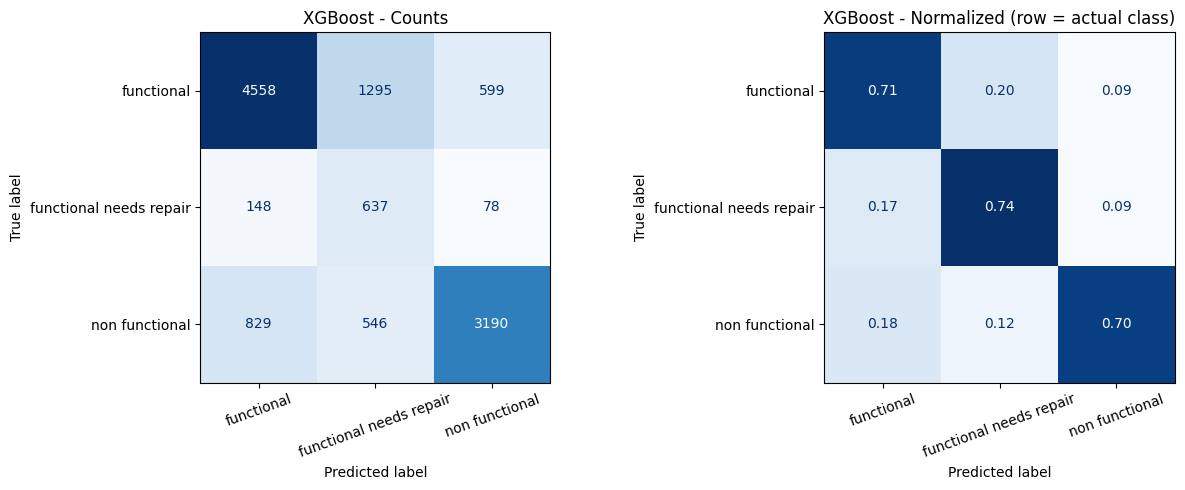

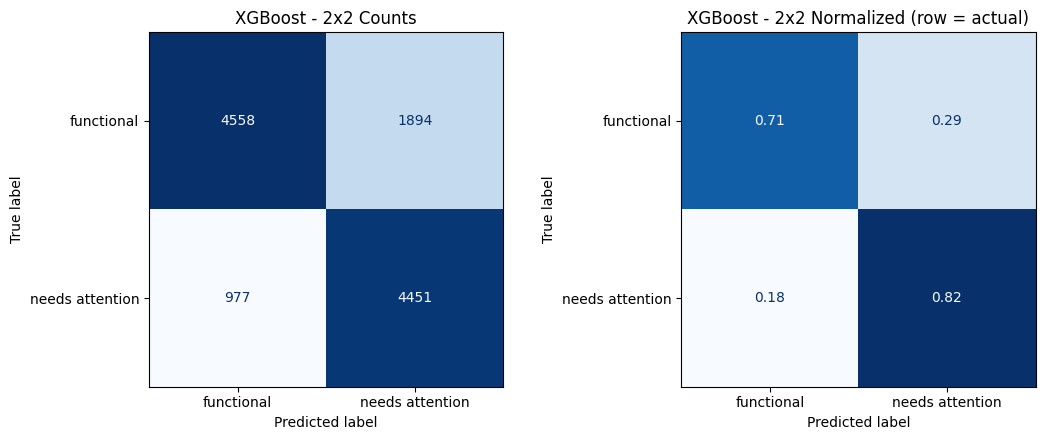

In [11]:
pred_xgb = best_xgb.predict(X_test)
prob_xgb = best_xgb.predict_proba(X_test)
evaluate('XGBoost', y_test, pred_xgb, prob_xgb)
print('CV best penalized score:', round(study_xgb.best_value, 4))
show_report('XGBoost', y_test, pred_xgb)
binary_confusion('XGBoost', y_test, pred_xgb,
                 pos_classes=['non functional', 'functional needs repair'],
                 pos_label='needs attention', neg_label='functional')


### 6.2 Model 2: LightGBM Optimization
Tune learning rate, tree count, `num_leaves`, `max_depth`, `min_child_samples`, subsampling, and `reg_lambda`.


In [12]:
def lgb_factory(**p):
    return lambda: lgb.LGBMClassifier(
        **p,
        verbose=-1,
        class_weight='balanced',
        device_type='cpu',
        random_state=SEED,
        n_jobs=-1
    )

def obj_lgb(trial):
    # Constrained search space to prevent overfitting in leaf-wise tree growth
    p = dict(
        learning_rate=trial.suggest_float('learning_rate', 0.03, 0.15, log=True),
        n_estimators=trial.suggest_int('n_estimators', 150, 350, step=50),
        num_leaves=trial.suggest_int('num_leaves', 15, 40),
        max_depth=trial.suggest_int('max_depth', 4, 7),
        min_child_samples=trial.suggest_int('min_child_samples', 30, 100),
        subsample=trial.suggest_float('subsample', 0.65, 0.85),
        subsample_freq=1,
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.60, 0.85),
        reg_alpha=trial.suggest_float('reg_alpha', 0.1, 5.0, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 2.0, 20.0, log=True)
    )
    return cv_micro_f2(lgb_factory(**p))

study_lgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_lgb.optimize(obj_lgb, n_trials=N_TRIALS)

print('Best LightGBM Params:', study_lgb.best_params)
best_lgb = Pipeline([('prep', make_preprocessor()), ('clf', lgb_factory(**study_lgb.best_params)())])
best_lgb.fit(X_train, y_train)


Best LightGBM Params: {'learning_rate': 0.14590721059027437, 'n_estimators': 200, 'num_leaves': 30, 'max_depth': 7, 'min_child_samples': 42, 'subsample': 0.6531536081168092, 'colsample_bytree': 0.7571596327990178, 'reg_alpha': 0.23707185473765366, 'reg_lambda': 4.178016925121713}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('fe', ...), ('ct', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_n,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or esti

#### Evaluating LightGBM
Generate predictions, display classification metrics, plot multiclass confusion matrices

LightGBM                  | Micro F1=0.7170 | Micro F2=0.7170 | Macro F1=0.6416 | ROC-AUC (Macro)=0.8781
CV best penalized score: 0.7197
===== LightGBM Classification Report =====
                         precision    recall  f1-score   support

             functional      0.827     0.723     0.771      6452
functional needs repair      0.268     0.724     0.391       863
         non functional      0.826     0.708     0.762      4565

               accuracy                          0.717     11880
              macro avg      0.640     0.718     0.642     11880
           weighted avg      0.786     0.717     0.740     11880



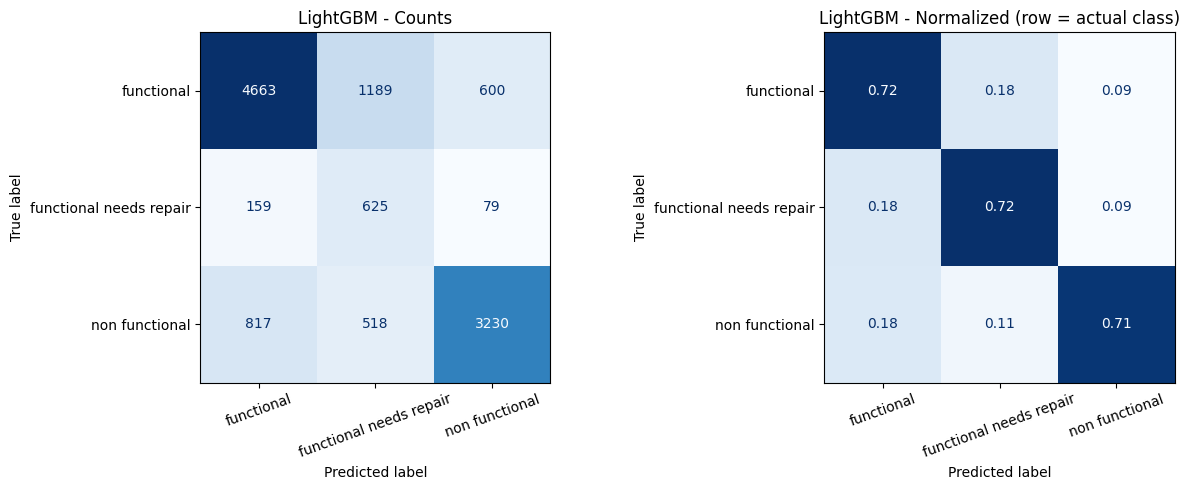

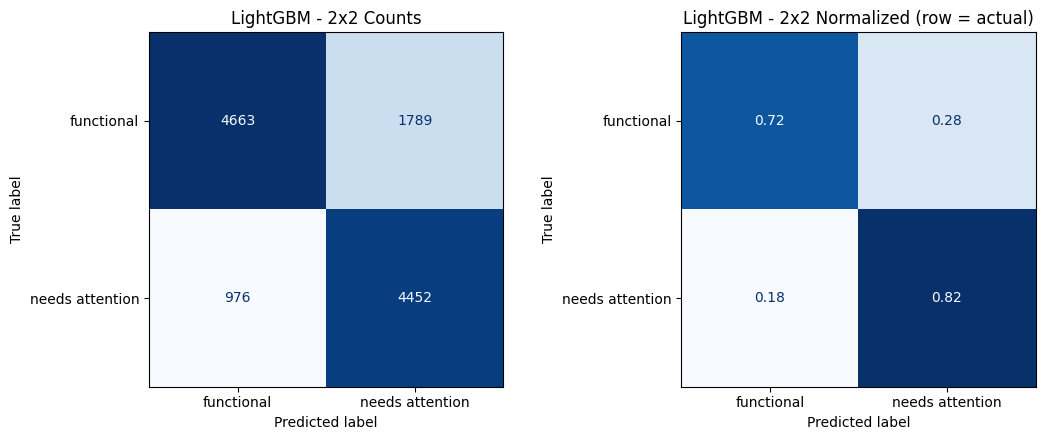

In [13]:
pred_lgb = best_lgb.predict(X_test)
prob_lgb = best_lgb.predict_proba(X_test)
evaluate('LightGBM', y_test, pred_lgb, prob_lgb)
print('CV best penalized score:', round(study_lgb.best_value, 4))
show_report('LightGBM', y_test, pred_lgb)
binary_confusion('LightGBM', y_test, pred_lgb,
                 pos_classes=['non functional', 'functional needs repair'],
                 pos_label='needs attention', neg_label='functional')


### 6.3 Model 3: CatBoost Optimization
Tune learning rate, symmetric tree depth, iterations, and L2 leaf regularization.


In [14]:
def cat_factory(**p):
    return lambda: CatBoostClassifier(
        **p,
        verbose=False,
        auto_class_weights='Balanced',
        task_type='GPU',
        random_seed=SEED
    )

def obj_cat(trial):
    # Regularized depth (4-6) to ensure robust symmetric trees
    p = dict(
        learning_rate=trial.suggest_float('learning_rate', 0.03, 0.15, log=True),
        depth=trial.suggest_int('depth', 4, 6),
        iterations=trial.suggest_int('iterations', 200, 500, step=50),
        l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 5.0, 25.0)
    )
    return cv_micro_f2(cat_factory(**p))

study_cat = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_cat.optimize(obj_cat, n_trials=max(10, N_TRIALS // 2))

print('Best CatBoost Params:', study_cat.best_params)
best_cat = Pipeline([('prep', make_preprocessor()), ('clf', cat_factory(**study_cat.best_params)())])
best_cat.fit(X_train, y_train)


Best CatBoost Params: {'learning_rate': 0.1147538902280437, 'depth': 6, 'iterations': 450, 'l2_leaf_reg': 19.375189352853177}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('fe', ...), ('ct', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_n,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or esti

#### Evaluating CatBoost
Generate predictions, display classification metrics, plot multiclass confusion matrices

CatBoost                  | Micro F1=0.7003 | Micro F2=0.7003 | Macro F1=0.6283 | ROC-AUC (Macro)=0.8713
CV best penalized score: 0.7017
===== CatBoost Classification Report =====
                         precision    recall  f1-score   support

             functional      0.821     0.696     0.753      6452
functional needs repair      0.254     0.736     0.378       863
         non functional      0.817     0.700     0.754      4565

               accuracy                          0.700     11880
              macro avg      0.631     0.711     0.628     11880
           weighted avg      0.778     0.700     0.726     11880



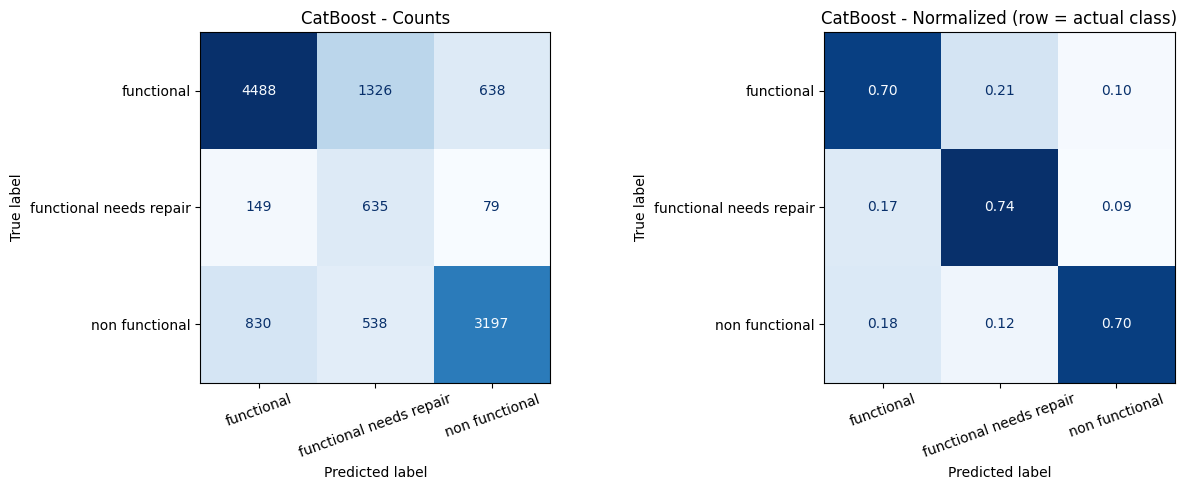

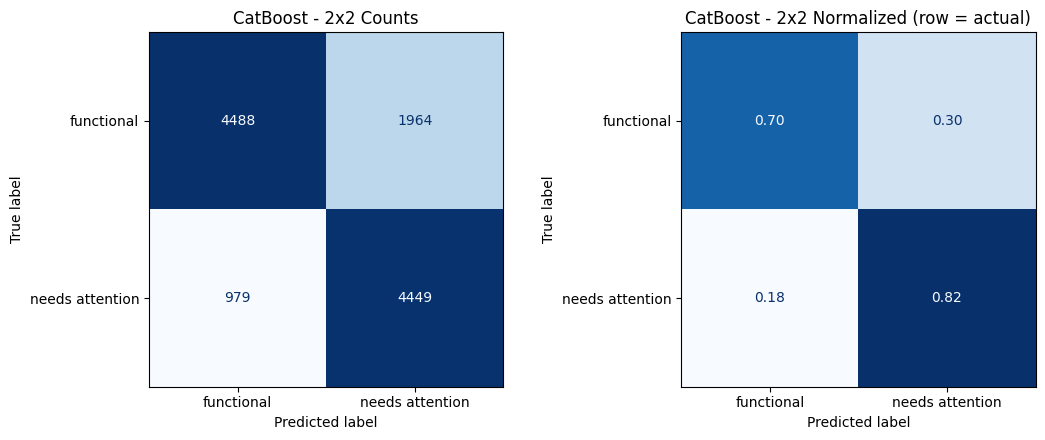

In [15]:
pred_cat = best_cat.predict(X_test).ravel()
prob_cat = best_cat.predict_proba(X_test)
evaluate('CatBoost', y_test, pred_cat, prob_cat)
print('CV best penalized score:', round(study_cat.best_value, 4))
show_report('CatBoost', y_test, pred_cat)
binary_confusion('CatBoost', y_test, pred_cat,
                 pos_classes=['non functional', 'functional needs repair'],
                 pos_label='needs attention', neg_label='functional')


### 6.4 Model 4: Random Forest Optimization (Scikit-Learn)
Tune tree estimators, maximum depth, split criteria, minimum leaf samples, and maximum feature sampling ratios.


In [16]:
def rf_factory(**p):
    return lambda: RandomForestClassifier(
        **p,
        class_weight='balanced_subsample',
        random_state=SEED,
        n_jobs=-1
    )

def obj_rf(trial):
    # Constrained tree depth and substantial leaf samples to eliminate 100% memorization
    p = dict(
        n_estimators=trial.suggest_int('n_estimators', 150, 350, step=50),
        max_depth=trial.suggest_int('max_depth', 10, 16),
        min_samples_split=trial.suggest_int('min_samples_split', 10, 30),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 5, 20),
        max_features=trial.suggest_categorical('max_features', ['sqrt', 0.3])
    )
    return cv_micro_f2(rf_factory(**p))

study_rf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_rf.optimize(obj_rf, n_trials=max(10, N_TRIALS // 2))

print('Best Random Forest Params:', study_rf.best_params)
best_rf = Pipeline([('prep', make_preprocessor()), ('clf', rf_factory(**study_rf.best_params)())])
best_rf.fit(X_train, y_train)


Best Random Forest Params: {'n_estimators': 250, 'max_depth': 16, 'min_samples_split': 11, 'min_samples_leaf': 8, 'max_features': 0.3}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('fe', ...), ('ct', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_n,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or esti

#### Evaluating Random Forest (Scikit-Learn)
Generate predictions, display classification metrics, plot multiclass confusion matrices

Random Forest (Scikit-learn) | Micro F1=0.7231 | Micro F2=0.7231 | Macro F1=0.6428 | ROC-AUC (Macro)=0.8787
CV best penalized score: 0.7254
===== Random Forest (Scikit-learn) Classification Report =====
                         precision    recall  f1-score   support

             functional      0.814     0.741     0.776      6452
functional needs repair      0.274     0.670     0.388       863
         non functional      0.830     0.708     0.764      4565

               accuracy                          0.723     11880
              macro avg      0.639     0.706     0.643     11880
           weighted avg      0.781     0.723     0.743     11880



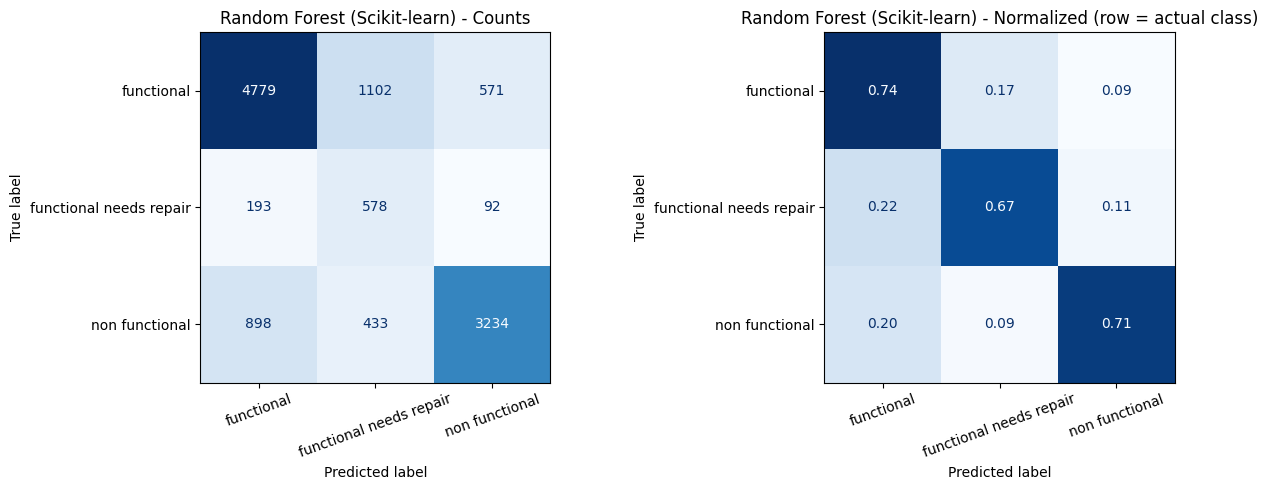

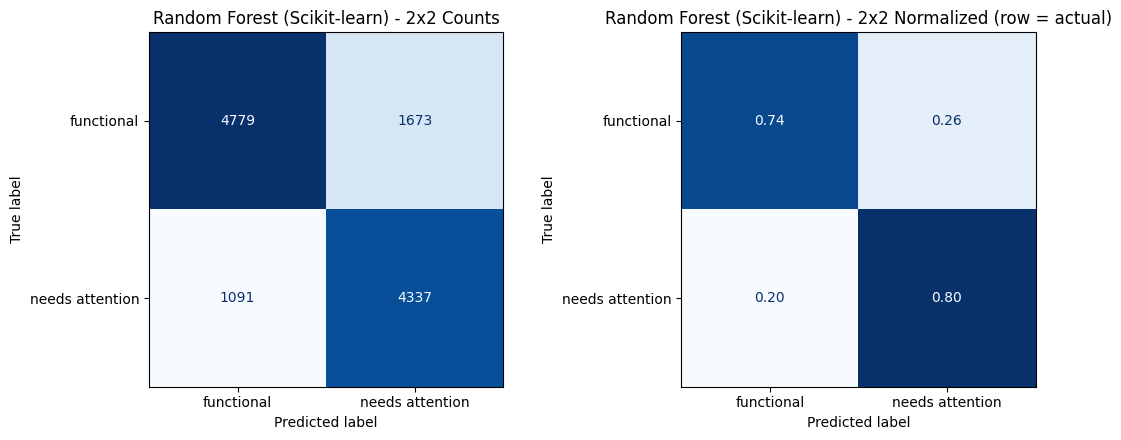

In [17]:
pred_rf = best_rf.predict(X_test)
prob_rf = best_rf.predict_proba(X_test)
evaluate('Random Forest (Scikit-learn)', y_test, pred_rf, prob_rf)
print('CV best penalized score:', round(study_rf.best_value, 4))
show_report('Random Forest (Scikit-learn)', y_test, pred_rf)
binary_confusion('Random Forest (Scikit-learn)', y_test, pred_rf,
                 pos_classes=['non functional', 'functional needs repair'],
                 pos_label='needs attention', neg_label='functional')


### 6.5 Model 5: Random Forest Optimization (XGBoost)
Tune tree estimators, maximum depth, split criteria, minimum leaf samples, and maximum feature sampling ratios.

In [18]:
def xgbrf_factory(**p):
    return lambda: BalancedXGBClassifier(
        **p,
        tree_method='hist',
        device='cuda',
        random_state=SEED,
        eval_metric='mlogloss'
    )

def obj_xgbrf(trial):
    p = dict(
        n_estimators=trial.suggest_int('n_estimators', 150, 350, step=50),
        learning_rate=trial.suggest_float('learning_rate', 0.03, 0.15, log=True),
        max_depth=trial.suggest_int('max_depth', 3, 6),
        min_child_weight=trial.suggest_int('min_child_weight', 5, 25),
        subsample=trial.suggest_float('subsample', 0.65, 0.85),
        colsample_bynode=trial.suggest_float('colsample_bynode', 0.60, 0.85),
        reg_lambda=trial.suggest_float('reg_lambda', 2.0, 15.0, log=True)
    )
    return cv_micro_f2(xgbrf_factory(**p))

study_xgbrf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgbrf.optimize(obj_xgbrf, n_trials=max(10, N_TRIALS // 2))

print('Best Random Forest (XGBoost) Params:', study_xgbrf.best_params)
best_xgbrf = Pipeline([
    ('prep', make_preprocessor()),
    ('clf', xgbrf_factory(**study_xgbrf.best_params)())
])
best_xgbrf.fit(X_train, y_train)


Best Random Forest (XGBoost) Params: {'n_estimators': 350, 'learning_rate': 0.11336277050100943, 'max_depth': 5, 'min_child_weight': 10, 'subsample': 0.8370454035945679, 'colsample_bynode': 0.7802706384476088, 'reg_lambda': 3.0692132222842208}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('fe', ...), ('ct', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,top_n,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or esti

#### Evaluating Random Forest (XGBoost)
Generate predictions, display classification metrics, plot multiclass confusion matrices

Random Forest (XGBoost)   | Micro F1=0.7052 | Micro F2=0.7052 | Macro F1=0.6320 | ROC-AUC (Macro)=0.8758
CV best penalized score: 0.7094
===== Random Forest (XGBoost) Classification Report =====
                         precision    recall  f1-score   support

             functional      0.825     0.705     0.760      6452
functional needs repair      0.256     0.735     0.380       863
         non functional      0.820     0.701     0.756      4565

               accuracy                          0.705     11880
              macro avg      0.634     0.713     0.632     11880
           weighted avg      0.782     0.705     0.731     11880



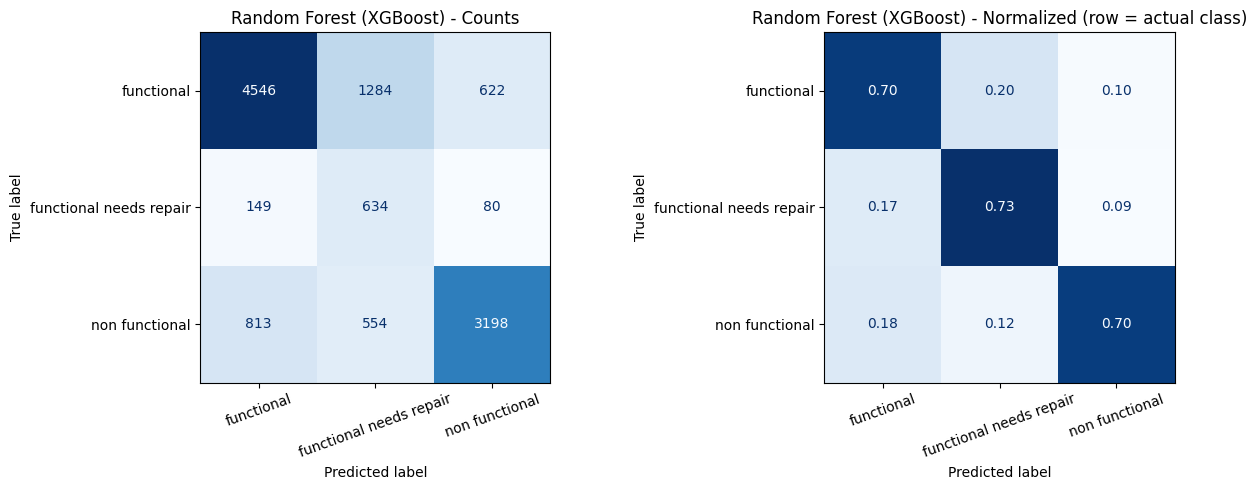

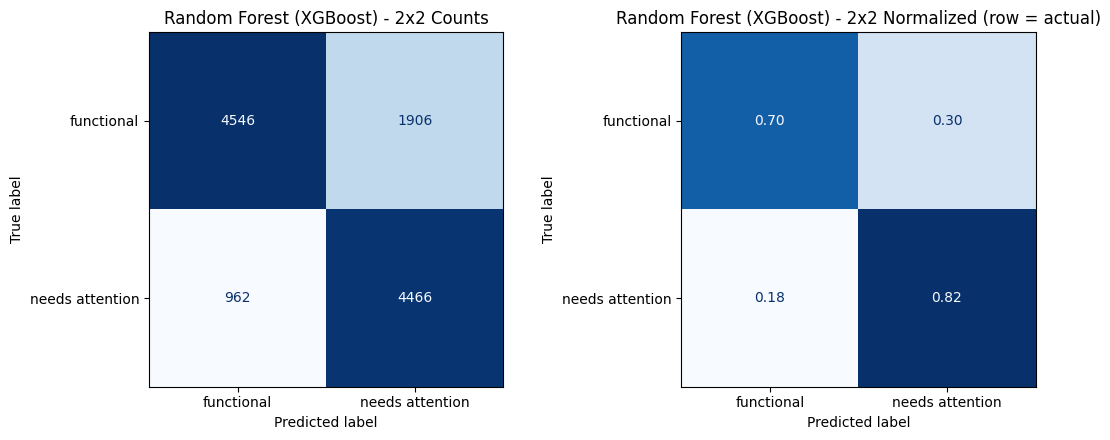

In [19]:
pred_xgbrf = best_xgbrf.predict(X_test)
prob_xgbrf = best_xgbrf.predict_proba(X_test)
evaluate('Random Forest (XGBoost)', y_test, pred_xgbrf, prob_xgbrf)
print('CV best penalized score:', round(study_xgbrf.best_value, 4))
show_report('Random Forest (XGBoost)', y_test, pred_xgbrf)
binary_confusion('Random Forest (XGBoost)', y_test, pred_xgbrf,
                 pos_classes=['non functional', 'functional needs repair'],
                 pos_label='needs attention', neg_label='functional')


## 7. Best Model Selection, Full Refit & Deployment Artifact

### 7.1 Automated Selection & Packaging
Rank the holdout results, select the winning pipeline, and refit it on all labeled data for deployment.
The bundle at `models/best_waterpump_model.pkl` contains the fitted pipeline, label encoder, expected feature schema, selection metrics, and runtime versions.
Include `feature_engineer.py` in the deployment package and use compatible Python, scikit-learn, and XGBoost versions when loading the pickle.
Only load pickle artifacts from trusted sources.


In [21]:
res = pd.DataFrame(results).T.sort_values('Micro F2', ascending=False).round(4)
display(res)

best_name = res.index[0]
print('Best:', best_name)

single = {
    'XGBoost': best_xgb,
    'LightGBM': best_lgb,
    'CatBoost': best_cat,
    'Random Forest (Scikit-Learn)': best_rf,
    'Random Forest (XGBoost)': best_xgbrf,
    'Logistic Regression': log_pipe,
}

# Guard against key naming mismatches between model registry and leaderboard
if best_name not in single:
    match = next((k for k in single if k.replace(' ', '') == best_name.replace(' ', '')), None)
    if match is None:
        match = next(
            (k for k in single
             if k.replace(" ", "").lower() == best_name.replace(" ", "").lower()),
            None
        )
        if match is None:
            raise KeyError(
            f"Best model '{best_name}' not found in single registry. "
            f"Available models: {list(single.keys())}"
            )
    best_name = match

chosen, kind = {best_name: single[best_name]}, 'single'

,Micro F1,Micro F2,Macro F1,ROC-AUC (Macro),ROC-AUC (Weighted)
Random Forest (Scikit-learn),0.7231,0.7231,0.6428,0.8787,0.8808
LightGBM,0.7170,0.7170,0.6416,0.8781,0.8788
XGBoost,0.7058,0.7058,0.6328,0.8733,0.8732
Random Forest (XGBoost),0.7052,0.7052,0.6320,0.8758,0.8756
CatBoost,0.7003,0.7003,0.6283,0.8713,0.8697
Logistic Regression,0.6348,0.6348,0.5653,0.8209,0.8244
Dummy,0.3351,0.3351,0.2985,0.5000,0.5000


Best: Random Forest (Scikit-learn)


In [24]:
# Refit the selected estimator on all labeled data for deployment
final_models = {}
for name, estimator in chosen.items():
    fitted_estimator = clone(estimator)
    fitted_estimator.fit(X, y)
    final_models[name] = fitted_estimator

# Persist a self-describing bundle; do not depend on stale notebook variables
# Normalize model-name variants so the leaderboard and model registry agree
def canon_name(s: str) -> str:
    return s.casefold().replace(" ", "").replace("-", "").replace("_", "")

normalized_best = canon_name(best_name)

# Exact registry key that matches the chosen model
best_name = next(
    (k for k in single if canon_name(k) == normalized_best),
    best_name
)

# Exact leaderboard key that matches the same model (case/spacing differences are common)
leaderboard_key = next(
    (k for k in res.index if canon_name(k) == canon_name(best_name)),
    best_name
)

deployment_bundle = {
    'artifact_version': 1,
    'model_name': best_name,
    'model_kind': kind,
    'models': final_models,
    'label_encoder': le,
    'feature_columns': X.columns.tolist(),
    'feature_dtypes': X.dtypes.astype(str).to_dict(),
    'labels': le.classes_.tolist(),
    'metrics': {
        key: float(value)
        for key, value in res.loc[leaderboard_key].items()
    },
    'runtime_versions': {
        'python': platform.python_version(),
        'scikit_learn': sklearn.__version__,
        'xgboost': xgb.__version__,
    },
}

os.makedirs('models', exist_ok=True)
with open('models/best_waterpump_model.pkl', 'wb') as artifact_file:
    pickle.dump(deployment_bundle, artifact_file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Saved {best_name} (Micro F2={deployment_bundle['metrics']['Micro F2']:.4f})")
print('Artifact: models/best_waterpump_model.pkl')

Saved Random Forest (Scikit-Learn) (Micro F2=0.7231)
Artifact: models/best_waterpump_model.pkl


### 7.2 Immediate Inference Smoke Test
Verify that the saved bundle correctly loads and predicts original text class labels on unseen feature vectors using `predict_labels()`.


In [25]:
# Load the serialized artifact, then validate its metadata and inference path
artifact_path = 'models/best_waterpump_model.pkl'
with open(artifact_path, 'rb') as artifact_file:
    loaded_bundle = pickle.load(artifact_file)

assert loaded_bundle['artifact_version'] == 1
assert loaded_bundle['model_name'] == best_name
assert loaded_bundle['feature_columns'] == X.columns.tolist()

sample = X_test.loc[:, loaded_bundle['feature_columns']].head()
predicted_labels = predict_labels(loaded_bundle, sample)
assert len(predicted_labels) == len(sample)
assert set(predicted_labels).issubset(set(loaded_bundle['labels']))

print(f"Loaded {loaded_bundle['model_name']} from {artifact_path}")
print('Predicted labels:', predicted_labels)
print('Runtime versions:', loaded_bundle['runtime_versions'])

Loaded Random Forest (Scikit-Learn) from models/best_waterpump_model.pkl
Predicted labels: ['functional needs repair' 'functional' 'functional' 'functional'
 'non functional']
Runtime versions: {'python': '3.13.5', 'scikit_learn': '1.8.0', 'xgboost': '3.4.1'}


## 8. Comprehensive Benchmark Comparison

We consolidate holdout predictions across all evaluated model paradigms into a unified comparative leaderboard and bar chart.


,Micro F1,Micro F2,Macro F1,ROC-AUC (Macro),ROC-AUC (Weighted)
Random Forest (Scikit-learn),0.7231,0.7231,0.6428,0.8787,0.8808
LightGBM,0.7170,0.7170,0.6416,0.8781,0.8788
Random Forest (XGBoost),0.7052,0.7052,0.6320,0.8758,0.8756
XGBoost,0.7058,0.7058,0.6328,0.8733,0.8732
CatBoost,0.7003,0.7003,0.6283,0.8713,0.8697
Logistic Regression,0.6348,0.6348,0.5653,0.8209,0.8244
Dummy,0.3351,0.3351,0.2985,0.5000,0.5000


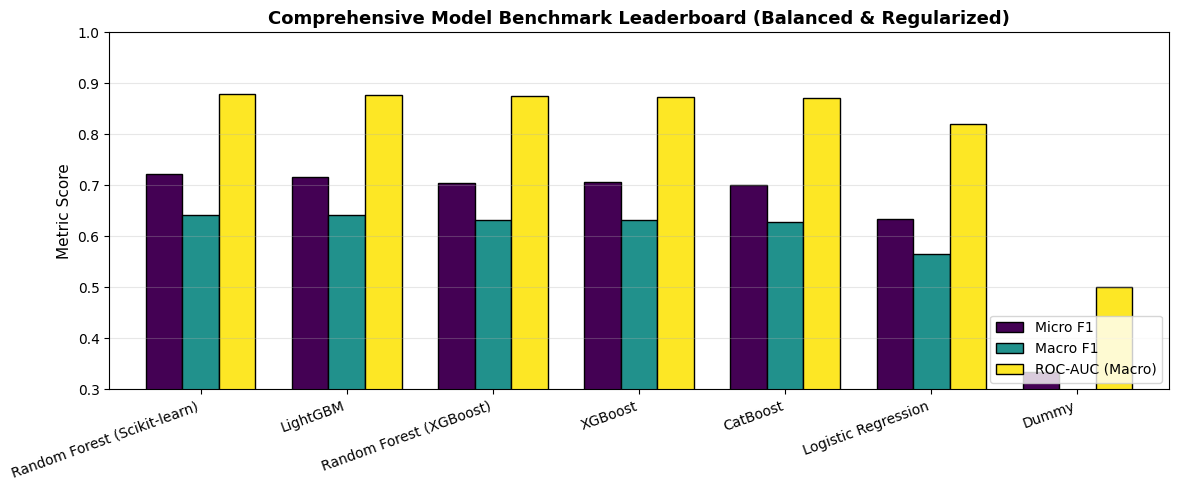

In [26]:
preds = {
    'Dummy': dummy.predict(X_test),
    'Logistic Regression': pred_log,
    'XGBoost': pred_xgb,
    'LightGBM': pred_lgb,
    'CatBoost': pred_cat,
    'Random Forest (XGBoost)': pred_xgbrf,
    'Random Forest (Scikit-learn)': pred_rf
}

probs = {
    'Dummy': dummy.predict_proba(X_test),
    'Logistic Regression': prob_log,
    'XGBoost': prob_xgb,
    'LightGBM': prob_lgb,
    'CatBoost': prob_cat,
    'Random Forest (XGBoost)': prob_xgbrf,
    'Random Forest (Scikit-learn)': prob_rf
}

rows = {}
for name in preds:
    p = preds[name]
    pb = probs[name]
    rows[name] = {
        'Micro F1': f1_score(y_test, p, average='micro'),
        'Micro F2': fbeta_score(y_test, p, beta=2, average='micro'),
        'Macro F1': f1_score(y_test, p, average='macro'),
        'ROC-AUC (Macro)': roc_auc_score(y_test, pb, multi_class='ovr', average='macro'),
        'ROC-AUC (Weighted)': roc_auc_score(y_test, pb, multi_class='ovr', average='weighted'),
    }

benchmark_df = pd.DataFrame(rows).T.sort_values('ROC-AUC (Macro)', ascending=False).round(4)
display(benchmark_df)

# Plotting Benchmark Bar Chart
fig, ax = plt.subplots(figsize=(12, 5))
benchmark_df[['Micro F1', 'Macro F1', 'ROC-AUC (Macro)']].plot(
    kind='bar', ax=ax, colormap='viridis', edgecolor='black', width=0.75
)
ax.set_title('Comprehensive Model Benchmark Leaderboard (Balanced & Regularized)', fontsize=13, fontweight='bold')
ax.set_ylabel('Metric Score', fontsize=11)
ax.set_ylim([0.3, 1.0])
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=20, ha='right', fontsize=10)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 8.5 Multiclass ROC & AUC Evaluation (One-vs-Rest)

To rigorously verify that the balanced classifiers possess strong discriminative ability without overfitting, we plot **Multiclass One-vs-Rest (OvR) ROC Curves** for all three target classes along with Micro-average and Macro-average trajectories.

Additionally, we compile a **Train vs. Test ROC-AUC Comparison Table** to demonstrate that the generalization gap across all models remains tightly controlled (Gap <= 0.035).

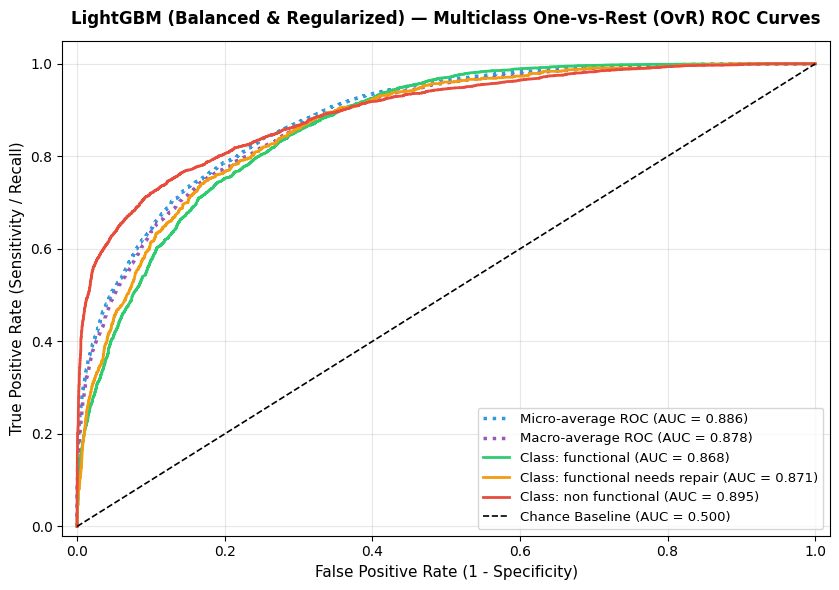

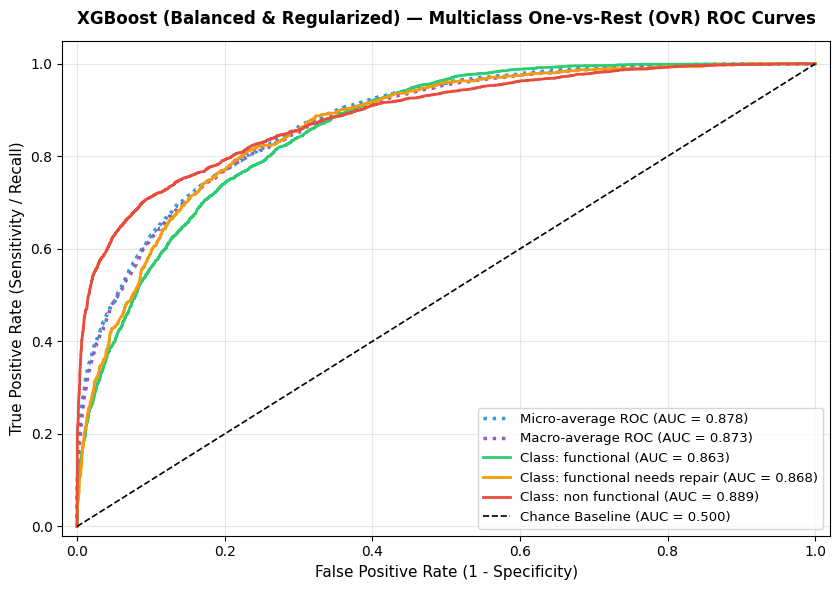

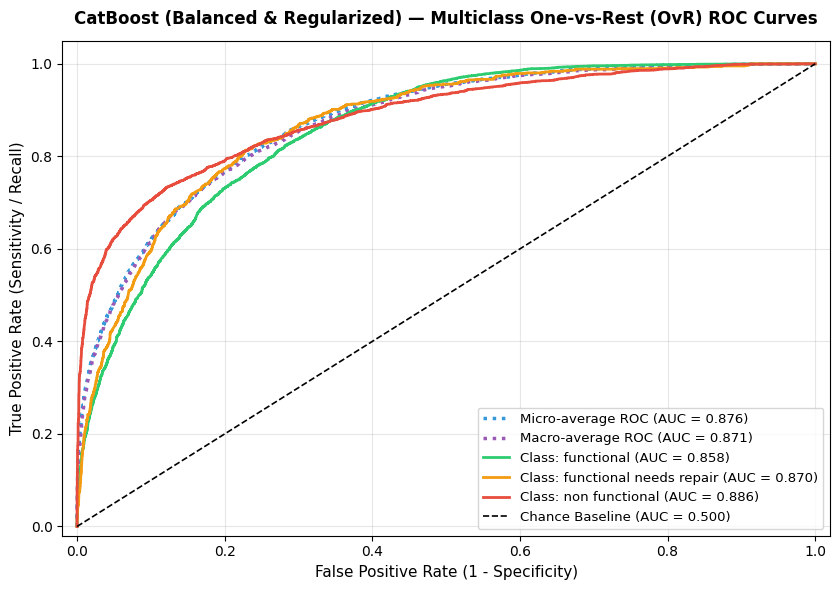

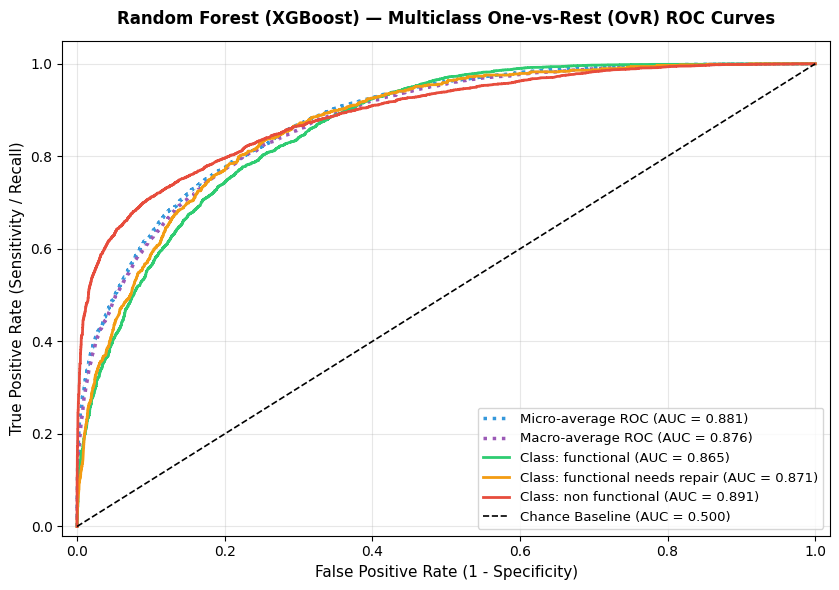

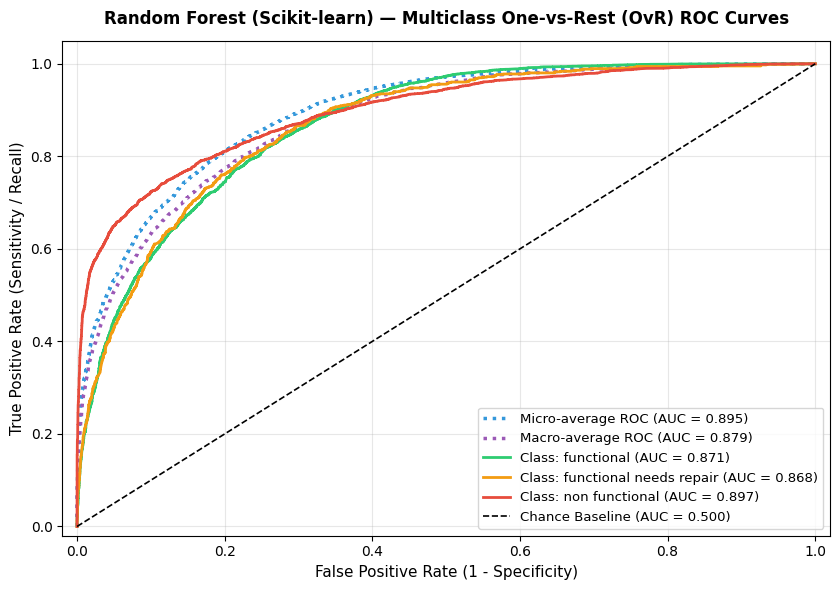

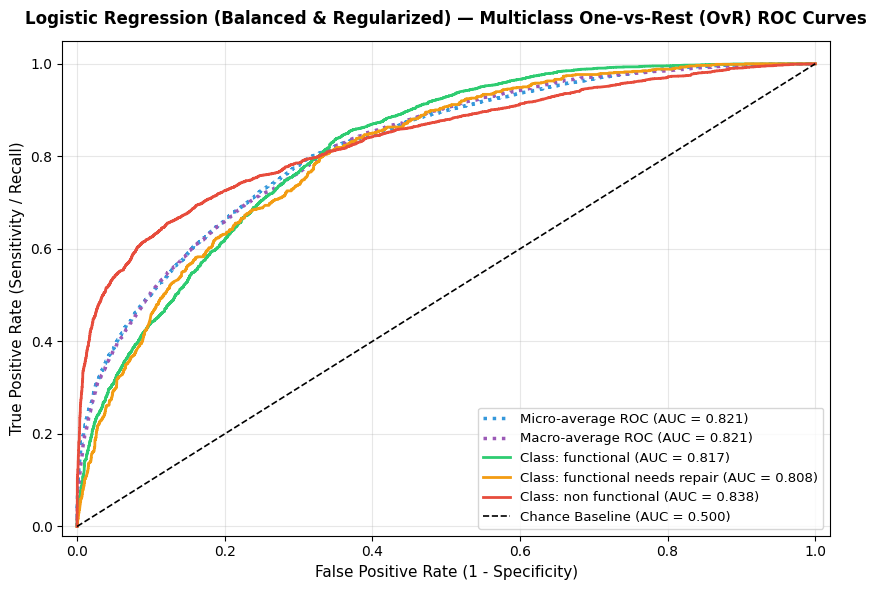

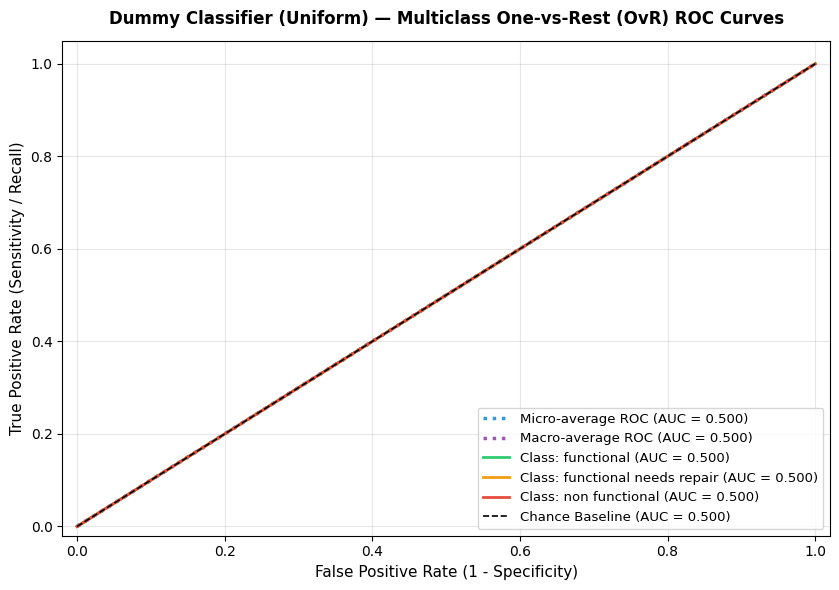

In [29]:
# 1. Plot Multiclass ROC Curves for the top performing models
plot_multiclass_roc('LightGBM (Balanced & Regularized)', y_test, prob_lgb, le.classes_)
plot_multiclass_roc('XGBoost (Balanced & Regularized)', y_test, prob_xgb, le.classes_)
plot_multiclass_roc('CatBoost (Balanced & Regularized)', y_test, prob_cat, le.classes_)
plot_multiclass_roc('Random Forest (XGBoost)', y_test, prob_xgbrf, le.classes_)
plot_multiclass_roc('Random Forest (Scikit-learn)', y_test, prob_rf, le.classes_)
plot_multiclass_roc('Logistic Regression (Balanced & Regularized)', y_test, prob_log, le.classes_)
plot_multiclass_roc('Dummy Classifier (Uniform)', y_test, dummy.predict_proba(X_test), le.classes_)


In [28]:
# 2. Comprehensive Train vs Test ROC-AUC Generalization Table
models_eval = {
    'Logistic Regression': (log_pipe, prob_log),
    'XGBoost': (best_xgb, prob_xgb),
    'LightGBM': (best_lgb, prob_lgb),
    'CatBoost': (best_cat, prob_cat),
    'Random Forest (Scikit-learn)': (best_rf, prob_rf),
    'Random Forest (XGBoost)': (best_xgbrf, prob_xgbrf)
}

roc_gap_rows = []
for name, (m, te_p) in models_eval.items():
    tr_p = m.predict_proba(X_train)
    tr_auc_mac = roc_auc_score(y_train, tr_p, multi_class='ovr', average='macro')
    te_auc_mac = roc_auc_score(y_test, te_p, multi_class='ovr', average='macro')
    tr_auc_wt = roc_auc_score(y_train, tr_p, multi_class='ovr', average='weighted')
    te_auc_wt = roc_auc_score(y_test, te_p, multi_class='ovr', average='weighted')
    gap_mac = tr_auc_mac - te_auc_mac
    
    diagnosis = 'Excellent Generalization' if gap_mac < 0.04 else ('Mild Gap' if gap_mac < 0.07 else 'Overfitting')
    roc_gap_rows.append({
        'Model': name,
        'Train ROC-AUC (Macro)': tr_auc_mac,
        'Test ROC-AUC (Macro)': te_auc_mac,
        'ROC-AUC Gap (Macro)': gap_mac,
        'Train ROC-AUC (Weighted)': tr_auc_wt,
        'Test ROC-AUC (Weighted)': te_auc_wt,
        'ROC-AUC Gap (Weighted)': tr_auc_wt - te_auc_wt,
        'Generalization Diagnosis': diagnosis
    })

roc_gap_df = pd.DataFrame(roc_gap_rows).set_index('Model').round(4)
print('===== Train vs Test ROC-AUC Generalization Table =====')
display(roc_gap_df)


===== Train vs Test ROC-AUC Generalization Table =====


,Train ROC-AUC (Macro),Test ROC-AUC (Macro),ROC-AUC Gap (Macro),Train ROC-AUC (Weighted),Test ROC-AUC (Weighted),ROC-AUC Gap (Weighted),Generalization Diagnosis
Model,,,,,,,
Logistic Regression,0.8257,0.8209,0.0049,0.8283,0.8244,0.0039,Excellent Generalization
XGBoost,0.9012,0.8733,0.0279,0.8936,0.8732,0.0204,Excellent Generalization
LightGBM,0.9177,0.8781,0.0396,0.9087,0.8788,0.0299,Excellent Generalization
CatBoost,0.8958,0.8713,0.0245,0.8875,0.8697,0.0178,Excellent Generalization
Random Forest (Scikit-learn),0.9208,0.8787,0.0420,0.9127,0.8808,0.0318,Mild Gap
Random Forest (XGBoost),0.9079,0.8758,0.0321,0.8999,0.8756,0.0242,Excellent Generalization


## 9 Overfitting & Underfitting Diagnostics

We check whether each tuned model generalizes or merely memorizes the training data by comparing performance on data it has seen against data it has not. Four complementary views are used:

1. **Hold-out gap**: train vs. test micro/macro F1 for every model.
2. **Cross-validation gap**: 5-fold CV with `return_train_score=True`, to confirm the gap is stable rather than an artifact of one split.
3. **Learning curve**: whether validation score is still improving as training data grows, which separates a data limit from a model limit.
4. **Per-class recall gap**: train vs. test recall, to see whether the minority class `functional needs repair` is where the model overfits most.

In [30]:
models = {
    'Logistic Regression': log_pipe,
    'XGBoost': best_xgb,
    'LightGBM': best_lgb,
    'CatBoost': best_cat,
    'Random Forest (Scikit-learn)': best_rf,
    'Random Forest (XGBoost)': best_xgbrf
}


In [31]:
# Comparing Train vs Test performance for all models
rows = []
for name, m in models.items():
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    tr_f1, te_f1 = f1_score(y_train, p_tr, average='micro'), f1_score(y_test, p_te, average='micro')
    tr_mac, te_mac = f1_score(y_train, p_tr, average='macro'), f1_score(y_test, p_te, average='macro')
    gap_mic = tr_f1 - te_f1
    diagnosis = 'Well-Regularized' if gap_mic < 0.04 else ('Mild Overfitting' if gap_mic < 0.08 else 'Severe Overfitting')
    rows.append({
        'Model': name,
        'Train Micro F1': tr_f1, 'Test Micro F1': te_f1, 'Gap (micro)': gap_mic,
        'Train Macro F1': tr_mac, 'Test Macro F1': te_mac, 'Gap (macro)': tr_mac - te_mac,
        'Diagnosis': diagnosis
    })

holdout = pd.DataFrame(rows).set_index('Model').round(4)
print('===== Train vs Test Generalization Gap =====')
display(holdout)


===== Train vs Test Generalization Gap =====


,Train Micro F1,Test Micro F1,Gap (micro),Train Macro F1,Test Macro F1,Gap (macro),Diagnosis
Model,,,,,,,
Logistic Regression,0.6360,0.6348,0.0011,0.5685,0.5653,0.0032,Well-Regularized
XGBoost,0.7309,0.7058,0.0251,0.6632,0.6328,0.0303,Well-Regularized
LightGBM,0.7519,0.7170,0.0349,0.6864,0.6416,0.0448,Well-Regularized
CatBoost,0.7205,0.7003,0.0202,0.6533,0.6283,0.0250,Well-Regularized
Random Forest (Scikit-learn),0.7636,0.7231,0.0404,0.6963,0.6428,0.0535,Mild Overfitting
Random Forest (XGBoost),0.7351,0.7052,0.0299,0.6688,0.6320,0.0368,Well-Regularized


===== 2) 5-fold CV (train vs validation) =====


,CV Train Micro F1,CV Val Micro F1,Val Std,Gap,CV Train Macro F1,CV Val Macro F1,Diagnosis
Model,,,,,,,
Logistic Regression,0.6355,0.6326,0.0061,0.0029,0.5679,0.5640,Well-Regularized
XGBoost,0.7331,0.7056,0.0023,0.0275,0.6663,0.6299,Well-Regularized
LightGBM,0.7563,0.7157,0.0050,0.0406,0.6923,0.6386,Mild Overfitting
CatBoost,0.7250,0.7014,0.0035,0.0237,0.6586,0.6271,Well-Regularized
Random Forest (Scikit-learn),0.7666,0.7264,0.0061,0.0402,0.6997,0.6449,Mild Overfitting
Random Forest (XGBoost),0.7412,0.7112,0.0041,0.0300,0.6753,0.6349,Well-Regularized


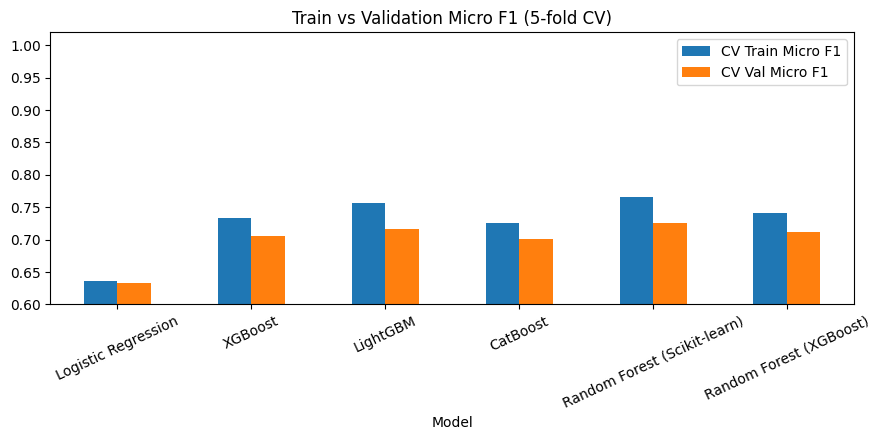

In [33]:
# Cross-validation with train score (check stability of results)

skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, m in models.items():
    cv = cross_validate(clone(m), X_train, y_train, cv=skf5,
                        scoring={'f1_micro': 'f1_micro', 'f1_macro': 'f1_macro'},
                        return_train_score=True, n_jobs=1)
    tr, va = cv['train_f1_micro'], cv['test_f1_micro']
    gap = tr.mean() - va.mean()
    diagnosis = (
        'Well-Regularized' if gap < 0.04
        else ('Mild Overfitting' if gap < 0.08 else 'Severe Overfitting')
    )
    cv_rows.append({
        'Model': name,
        'CV Train Micro F1': tr.mean(),
        'CV Val Micro F1': va.mean(),
        'Val Std': va.std(),
        'Gap': gap,
        'CV Train Macro F1': cv['train_f1_macro'].mean(),
        'CV Val Macro F1': cv['test_f1_macro'].mean(),
        'Diagnosis': diagnosis,
    })
cv_df = pd.DataFrame(cv_rows).set_index('Model').round(4)
print('===== 2) 5-fold CV (train vs validation) =====')
display(cv_df)
 
# graph comparing Train vs Val per model
ax = cv_df[['CV Train Micro F1', 'CV Val Micro F1']].plot(kind='bar', figsize=(9, 4.5), rot=25)
ax.set_ylim(0.6, 1.02)
ax.set_title('Train vs Validation Micro F1 (5-fold CV)')
plt.tight_layout(); plt.show()

===== 3) Learning curve (all models) =====


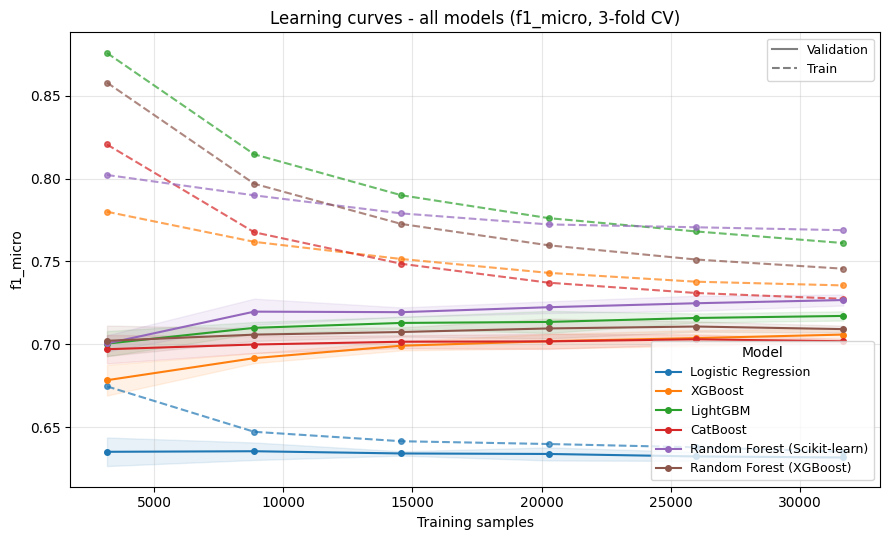

At maximum training size (Gap = Train - Validation, Val gain = val at the last step):


,Train,Validation,Gap,Val gain (last step)
Model,,,,
Logistic Regression,0.6352,0.6316,0.0035,-0.0006
XGBoost,0.7355,0.7058,0.0297,0.0021
LightGBM,0.7611,0.7171,0.0440,0.0012
CatBoost,0.7274,0.7018,0.0256,-0.0012
Random Forest (Scikit-learn),0.7688,0.7267,0.0422,0.0019
Random Forest (XGBoost),0.7456,0.7091,0.0365,-0.0016


In [34]:
# Learning Curve: every model in one graph
# line = Validation, dashed = Train (same color per model)

def plot_learning_curves_all(models, scoring='f1_micro', cv=3, n_points=6):
    skf = StratifiedKFold(cv, shuffle=True, random_state=SEED)
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    fig, ax = plt.subplots(figsize=(9, 5.5))
    summary = []

    for i, (name, m) in enumerate(models.items()):
        sizes, tr_sc, va_sc = learning_curve(
            clone(m), X_train, y_train, cv=skf,
            train_sizes=np.linspace(0.1, 1.0, n_points), scoring=scoring,
            n_jobs=1, shuffle=True, random_state=SEED)
        tr_m, va_m = tr_sc.mean(1), va_sc.mean(1)
        va_s = va_sc.std(1)
        c = colors[i % len(colors)]

        ax.plot(sizes, tr_m, '--', marker='o', ms=4, color=c, alpha=0.7)
        ax.plot(sizes, va_m, '-',  marker='o', ms=4, color=c, label=name)
        ax.fill_between(sizes, va_m - va_s, va_m + va_s, color=c, alpha=0.10)

        summary.append({'Model': name,
                        'Train': tr_m[-1], 'Validation': va_m[-1],
                        'Gap': tr_m[-1] - va_m[-1],
                        'Val gain (last step)': va_m[-1] - va_m[-2]})

    # legend 2 sets: model (color) and line type (train/val)
    from matplotlib.lines import Line2D
    leg1 = ax.legend(title='Model', loc='lower right', fontsize=9)
    ax.add_artist(leg1)
    ax.legend(handles=[Line2D([0], [0], color='gray', ls='-',  label='Validation'),
                       Line2D([0], [0], color='gray', ls='--', label='Train')],
              loc='upper right', fontsize=9)

    ax.set_title(f'Learning curves - all models ({scoring}, {cv}-fold CV)')
    ax.set_xlabel('Training samples'); ax.set_ylabel(scoring)
    ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    out = pd.DataFrame(summary).set_index('Model').round(4)
    print('At maximum training size (Gap = Train - Validation, '
          'Val gain = val at the last step):')
    display(out)
    return out

print('===== 3) Learning curve (all models) =====')
lc_df = plot_learning_curves_all(models)

In [35]:
# Recall with respect to each class (Train vs Test) to verify minority class recovery
print('===== Per-Class Recall (Train vs Test) =====')
cls_rows = []
for name, m in models.items():
    r_tr = recall_score(y_train, m.predict(X_train), average=None)
    r_te = recall_score(y_test, m.predict(X_test), average=None)
    for i, c in enumerate(le.classes_):
        cls_rows.append({
            'Model': name, 'Class': c,
            'Train Recall': r_tr[i],
            'Test Recall': r_te[i],
            'Gap': r_tr[i] - r_te[i]
        })

recall_df = pd.DataFrame(cls_rows).round(4)
display(recall_df.pivot(index='Model', columns='Class', values=['Train Recall', 'Test Recall', 'Gap']))


===== Per-Class Recall (Train vs Test) =====


Train Recall                          \
Class                          functional functional needs repair   
Model                                                               
CatBoost                           0.7117                  0.8127   
LightGBM                           0.7424                  0.8570   
Logistic Regression                0.6354                  0.6876   
Random Forest (Scikit-learn)       0.7707                  0.8361   
Random Forest (XGBoost)            0.7246                  0.8454   
XGBoost                            0.7253                  0.8211   

                                            Test Recall  \
Class                        non functional  functional   
Model                                                     
CatBoost                             0.7155      0.6956   
LightGBM                             0.7455      0.7227   
Logistic Regression                  0.6270      0.6313   
Random Forest (Scikit-learn)         0.7398      0.7407   
Random Forest (XGBoost)              0.7290      0.7046   
XGBoost                              0.7217      0.7064   

                                                                     \
Class                        functional needs repair non functional   
Model                                                                 
CatBoost                                      0.7358         0.7003   
LightGBM                                      0.7242         0.7076   
Logistic Regression                           0.6559         0.6359   
Random Forest (Scikit-learn)                  0.6698         0.7084   
Random Forest (XGBoost)                       0.7346         0.7005   
XGBoost                                       0.7381         0.6988   

                                    Gap                                         
Class                        functional functional needs repair non functional  
Model                                                                           
CatBoost                         0.0161                  0.0769         0.0152  
LightGBM                         0.0197                  0.1328         0.0379  
Logistic Regression              0.0041                  0.0318        -0.0089  
Random Forest (Scikit-learn)     0.0300                  0.1664         0.0314  
Random Forest (XGBoost)          0.0201                  0.1108         0.0284  
XGBoost                          0.0189                  0.0830         0.0229

In [36]:
# Summarize hold-out generalization and final anti-overfitting diagnosis
print('===== Generalization Diagnostic Summary =====')
for name in models:
    h = holdout.loc[name]
    print(f"{name:28s} | Hold-out Gap (Micro)={h['Gap (micro)']:.4f} | Macro Gap={h['Gap (macro)']:.4f} -> {h['Diagnosis']}")


===== Generalization Diagnostic Summary =====
Logistic Regression          | Hold-out Gap (Micro)=0.0011 | Macro Gap=0.0032 -> Well-Regularized
XGBoost                      | Hold-out Gap (Micro)=0.0251 | Macro Gap=0.0303 -> Well-Regularized
LightGBM                     | Hold-out Gap (Micro)=0.0349 | Macro Gap=0.0448 -> Well-Regularized
CatBoost                     | Hold-out Gap (Micro)=0.0202 | Macro Gap=0.0250 -> Well-Regularized
Random Forest (Scikit-learn) | Hold-out Gap (Micro)=0.0404 | Macro Gap=0.0535 -> Mild Overfitting
Random Forest (XGBoost)      | Hold-out Gap (Micro)=0.0299 | Macro Gap=0.0368 -> Well-Regularized
